# Baseline Models: Random Forest

This notebook will use a Random Forest classifier to identify illicit Bitcoin transactions in the Elliptic dataset. We will train the model, evaluate its performance, experiment with class weighting and compare the results.

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    log_loss,
    average_precision_score)

##Preparing the Data

We will use the 165 transaction features as model inputs (X) and use the target column (y) as the classification label (0 = licit, 1 = illicit). We use the chronological data split created during preprocessing. Transaction IDs, time steps, and split labels are not included in the model features.

In [29]:
#load processed dataset
data = pd.read_csv("elliptic_labeled_processed.csv.gz")

In [30]:
# 165 transaction features
feature_cols = [col for col in data.columns if col.startswith("feature_")]

#chronological time based split
train_data = data[data["split"] == "train"]
val_data = data[data["split"] == "validation"]
test_data = data[data["split"] == "test"]

#separate features X and y
X_train = train_data[feature_cols]
y_train = train_data["target"]

X_val = val_data[feature_cols]
y_val = val_data["target"]

X_test = test_data[feature_cols]
y_test = test_data["target"]

print("Number of features:", len(feature_cols))
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Number of features: 165
Training set: (29894, 165)
Validation set: (7829, 165)
Test set: (8841, 165)


##Baseline Random Forest Model

We train a simple Random Forest classifier using 100 decision trees and a maximum tree depth of 10. The depth helps us to control model complexity and reduce the risk of overfitting.

In [56]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth = 10, random_state=42)

In [57]:
rf_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, random_state=42)

##Evaluating the Random Forest Model

We will look at accuracy, precision, recall, F1 score, log loss, and PR-AUC. Since illicit transactions are the minority class, we will look a bit more closely at precision, recall, F1, and PR-AUC.

In [58]:
rf_train_pred = rf_model.predict(X_train)
print("Random Forest Training Results")
print("Accuracy:", accuracy_score(y_train, rf_train_pred))
print("Precision:", precision_score(y_train, rf_train_pred))
print("Recall:", recall_score(y_train, rf_train_pred))
print("F1 Score:", f1_score(y_train, rf_train_pred))

Random Forest Training Results
Accuracy: 0.9928413728507393
Precision: 0.9966360856269113
Recall: 0.9413633737723859
F1 Score: 0.9682115270350564


In [59]:
rf_val_pred = rf_model.predict(X_val)
rf_val_prob = rf_model.predict_proba(X_val)

In [60]:
print("Random Forest Validation Results")
print("Accuracy:", accuracy_score(y_val, rf_val_pred))
print("Precision:", precision_score(y_val, rf_val_pred))
print("Recall:", recall_score(y_val, rf_val_pred))
print("F1 Score:", f1_score(y_val, rf_val_pred))
print("Log Loss:", log_loss(y_val, rf_val_prob))
print("PR-AUC:", average_precision_score(y_val, rf_val_prob[:, 1]))

Random Forest Validation Results
Accuracy: 0.9869715161578746
Precision: 0.9751243781094527
Recall: 0.8711111111111111
F1 Score: 0.92018779342723
Log Loss: 0.08044952630497308
PR-AUC: 0.9253285166873485


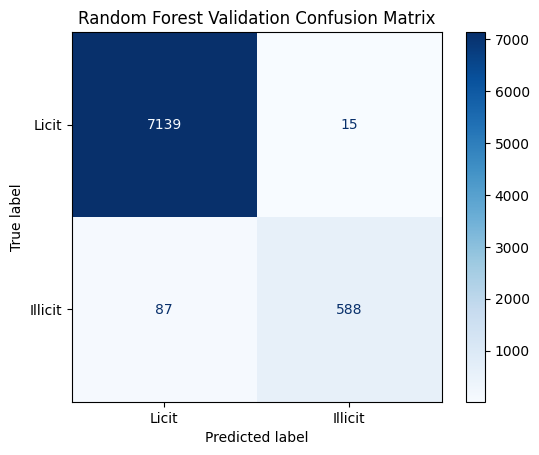

In [61]:
cm = confusion_matrix(y_val, rf_val_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Licit", "Illicit"])
disp.plot(cmap="Blues")
plt.title("Random Forest Validation Confusion Matrix")
plt.show()

##Random Forest with Class Weighting

Because the dataset is imbalanced, more licit transactions than illicit transactions. We can try to use class_weight="balanced" to give more importance to the minority class during our training.

In [62]:
rf_balanced = RandomForestClassifier(n_estimators=100, max_depth = 10, random_state=42, class_weight="balanced")
rf_balanced.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10, random_state=42)

In [63]:
rf_balanced_train_pred = rf_balanced.predict(X_train)
print("Balanced Random Forest Training Results")
print("Accuracy:", accuracy_score(y_train, rf_balanced_train_pred))
print("Precision:", precision_score(y_train, rf_balanced_train_pred))
print("Recall:", recall_score(y_train, rf_balanced_train_pred))
print("F1 Score:", f1_score(y_train, rf_balanced_train_pred))

Balanced Random Forest Training Results
Accuracy: 0.9933431457817622
Precision: 0.9540773726690788
Recall: 0.9901790872328134
F1 Score: 0.9717930545712261


In [64]:
rf_balanced_pred = rf_balanced.predict(X_val)
rf_balanced_prob = rf_balanced.predict_proba(X_val)

Balanced Random Forest Validation Results
Accuracy: 0.9656405671222378
Precision: 0.7550251256281407
Recall: 0.8903703703703704
F1 Score: 0.8171312032630863
Log Loss: 0.11752992758011223
PR-AUC: 0.9141969433623232


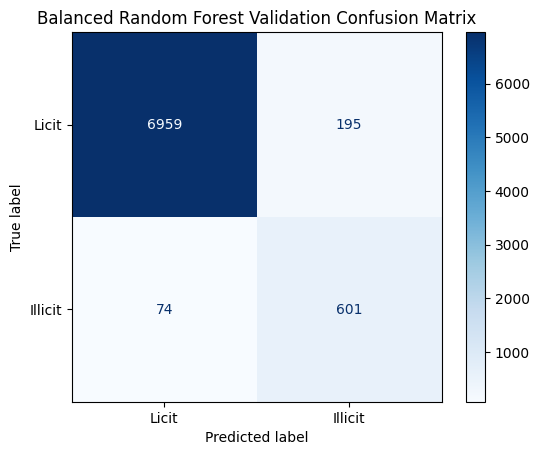

In [65]:
print("Balanced Random Forest Validation Results")
print("Accuracy:", accuracy_score(y_val, rf_balanced_pred))
print("Precision:", precision_score(y_val, rf_balanced_pred))
print("Recall:", recall_score(y_val, rf_balanced_pred))
print("F1 Score:", f1_score(y_val, rf_balanced_pred))
print("Log Loss:", log_loss(y_val, rf_balanced_prob))
print("PR-AUC:", average_precision_score(y_val, rf_balanced_prob[:, 1]))

cm_balanced = confusion_matrix(y_val, rf_balanced_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_balanced, display_labels=["Licit", "Illicit"])
disp.plot(cmap="Blues")
plt.title("Balanced Random Forest Validation Confusion Matrix")
plt.show()

##Final Evaluation

We will evaluate the baseline Random Forest model on the test set to see how well it generalizes to unseen, later transactions.


Random Forest Final Test Results
Accuracy: 0.9729668589526071
Precision: 0.8930232558139535
Recall: 0.47058823529411764
F1 Score: 0.6163723916532905
Log Loss: 0.14192170664339526
PR-AUC: 0.5297380796060355


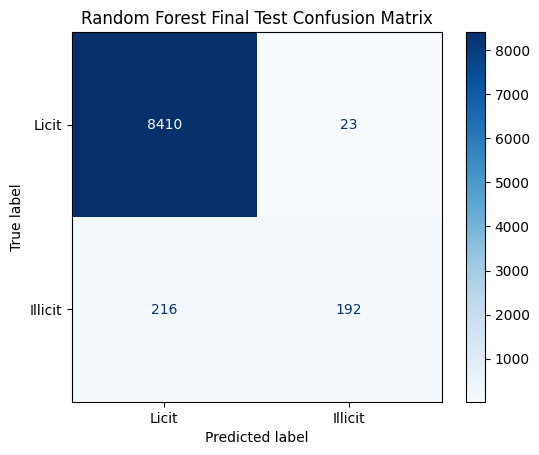

In [66]:
rf_test_pred = rf_model.predict(X_test)
rf_test_prob = rf_model.predict_proba(X_test)

#final test performance
print("Random Forest Final Test Results")
print("Accuracy:", accuracy_score(y_test, rf_test_pred))
print("Precision:", precision_score(y_test, rf_test_pred))
print("Recall:", recall_score(y_test, rf_test_pred))
print("F1 Score:", f1_score(y_test, rf_test_pred))
print("Log Loss:", log_loss(y_test, rf_test_prob))
print("PR-AUC:", average_precision_score(y_test, rf_test_prob[:, 1]))

cm_test = confusion_matrix(y_test, rf_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=["Licit", "Illicit"])
disp.plot(cmap="Blues")
plt.title("Random Forest Final Test Confusion Matrix")
plt.show()